<a href="https://colab.research.google.com/github/NetanelFarhi/mura-wrist-ml-pipeline/blob/ARTEM/01_MURA_Data_Preparation_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

# Colab runs on Linux: Google Drive is mounted under /content/drive/MyDrive (no space, forward slashes)
PROJECT_DIR = "/content/drive/MyDrive/BAR ILAN/Projects/RENTGEN/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA"

print("Project directory:")
print(PROJECT_DIR)

if os.path.isdir(PROJECT_DIR):
    print("\n✓ PASS: Project directory exists.")

    zip_files = []
    for root, dirs, files in os.walk(PROJECT_DIR):
        for file in files:
            if file.lower().endswith(".zip"):
                zip_files.append(os.path.join(root, file))

    if zip_files:
        print(f"\nFound {len(zip_files)} ZIP file(s):")
        for path in zip_files:
            print(path)
    else:
        print("\n⚠ No ZIP files found in the project directory.")
else:
    print("\n✗ FAIL: Project directory was not found.")


Project directory:
/content/drive/MyDrive/BAR ILAN/Projects/RENTGEN/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA

✓ PASS: Project directory exists.

Found 1 ZIP file(s):
/content/drive/MyDrive/BAR ILAN/Projects/RENTGEN/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA-v1.1_files.zip


In [ ]:
import pandas as pd

CSV_PATH = "/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/mura_v1_1.csv"

df = pd.read_csv(CSV_PATH)

print("✓ MURA file-index table loaded successfully.")

print("\n=== DATASET SHAPE ===")
print(df.shape)

print("\n=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== DATAFRAME INFO ===")
df.info()

print("\n=== FIRST 5 ROWS ===")
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/mura_v1_1.csv'

In [ ]:
print("=== MURA FILE-INDEX PRE-TESTS ===\n")

expected_rows = 40013
expected_columns = 5
expected_column_names = [
    "file_id",
    "file_name",
    "size",
    "added_at",
    "md5_hash"
]

# 1. Dataset dimensions
print("1. DATASET DIMENSIONS")
print(f"Expected: ({expected_rows}, {expected_columns})")
print(f"Actual:   {df.shape}")

if df.shape == (expected_rows, expected_columns):
    print("✓ PASS: Dataset dimensions are correct.")
else:
    print("⚠ CHECK: Dataset dimensions differ from expected.")

# 2. Column names
print("\n2. COLUMN STRUCTURE")
print("Expected:", expected_column_names)
print("Actual:  ", df.columns.tolist())

if df.columns.tolist() == expected_column_names:
    print("✓ PASS: Column structure is correct.")
else:
    print("⚠ CHECK: Column structure differs from expected.")

# 3. Missing values
print("\n3. MISSING VALUES")
missing = df.isnull().sum()
print(missing)

if missing.sum() == 0:
    print("✓ PASS: No missing values detected.")
else:
    print("⚠ CHECK: Missing values detected.")

# 4. Duplicate rows
print("\n4. DUPLICATE ROWS")
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

if duplicates == 0:
    print("✓ PASS: No duplicate rows detected.")
else:
    print("⚠ CHECK: Duplicate rows detected.")

# 5. Unique file IDs
print("\n5. FILE ID UNIQUENESS")
print(f"Unique file IDs: {df['file_id'].nunique():,}")
print(f"Total rows:      {len(df):,}")

if df["file_id"].nunique() == len(df):
    print("✓ PASS: Every file_id is unique.")
else:
    print("⚠ CHECK: Duplicate file_id values detected.")

In [ ]:
import zipfile

print("\n=== ZIP FILE CONTENTS ===")
try:
    with zipfile.ZipFile(PROJECT_DIR, 'r') as zip_ref:
        zip_contents = zip_ref.namelist()
        print("First 5 files:")
        for i, item in enumerate(zip_contents):
            if i < 5:
                print(item)
            else:
                break
    print(f"\nTotal files in zip: {len(zip_contents)}")
except zipfile.BadZipFile:
    print(f"Error: The file at {PROJECT_DIR} is not a valid zip file.")
except FileNotFoundError:
    print(f"Error: The file at {PROJECT_DIR} was not found.")

In [ ]:
import zipfile

print("=== CSV ↔ ZIP CONSISTENCY CHECK ===\n")

with zipfile.ZipFile(PROJECT_DIR, "r") as z:
    zip_files = set(z.namelist())

csv_files = set(df["file_name"])

print(f"Files listed in CSV: {len(csv_files):,}")
print(f"Files contained in ZIP: {len(zip_files):,}")

missing_from_zip = csv_files - zip_files
missing_from_csv = zip_files - csv_files

print(f"\nCSV files missing from ZIP: {len(missing_from_zip):,}")
print(f"ZIP files missing from CSV: {len(missing_from_csv):,}")

if len(missing_from_zip) == 0 and len(missing_from_csv) == 0:
    print("\n✓ PASS: CSV and ZIP contain exactly the same files.")
else:
    print("\n⚠ CHECK: CSV and ZIP contents do not match exactly.")

In [ ]:
df['file_extension'] = df['file_name'].apply(lambda x: os.path.splitext(x)[1])

print("\n=== FILE TYPE DISTRIBUTION ===")
file_type_distribution = df['file_extension'].value_counts()
display(file_type_distribution)

The distribution of file types in your DataFrame has been successfully calculated and displayed:

    There are 40,009 files with the '.png' extension.
    There are 4 files with the '.csv' extension.

This indicates that the vast majority of your files are image files, with a small number of CSV files also present.

The ZIP contains 40,013 actual files, which matches the 40,013 rows in the CSV file-index table. The filenames show that the original MURA hierarchy is encoded directly in each path:

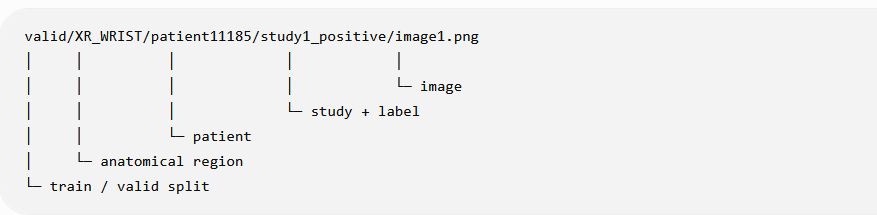

In [ ]:
# Select only wrist X-rays
wrist_df = df[
    df["file_name"].str.contains("XR_WRIST", na=False)
].copy()

# Preserve MURA's original train/validation split
train_df = wrist_df[
    wrist_df["file_name"].str.startswith("train/")
].copy()

valid_df = wrist_df[
    wrist_df["file_name"].str.startswith("valid/")
].copy()

print("=== MURA WRIST DATASET ===")
print(f"Total wrist images:      {len(wrist_df):,}")
print(f"Training images:         {len(train_df):,}")
print(f"Validation images:       {len(valid_df):,}")

# Pre-test
if len(wrist_df) == 10415 and len(train_df) == 9756 and len(valid_df) == 659:
    print("\n✓ PASS: Wrist dataset and original MURA split match expected counts.")
else:
    print("\n⚠ CHECK: Counts differ from expected values.")

## Wrist Training Population — Patient and Study-Level Analysis

Before creating the internal training and validation sets, the official MURA wrist
training population is analyzed at the patient and study levels.

Because MURA labels are assigned at the study level and multiple images may belong
to the same patient or study, the internal split will be performed at the patient
level to prevent data leakage.

The purpose of this analysis is to determine:
- the number of unique patients and studies,
- the number of normal and abnormal studies,
- the number of images per class,
- whether an 80/20 patient-level split provides a sufficiently large internal
  validation set for model and operating-threshold selection.

In [ ]:
import pandas as pd
import re

# Use only official MURA wrist training images
wrist_train = df[
    df["file_name"].str.startswith("train/XR_WRIST/", na=False)
].copy()

print("=== OFFICIAL MURA WRIST TRAINING DATA ===")
print(f"Images: {len(wrist_train):,}")

# Extract information encoded in the MURA file path
wrist_train["patient_id"] = wrist_train["file_name"].str.extract(
    r"(patient\d+)"
)[0]

wrist_train["study_id"] = wrist_train["file_name"].str.extract(
    r"(study\d+_(?:positive|negative))"
)[0]

wrist_train["label"] = wrist_train["file_name"].str.extract(
    r"study\d+_(positive|negative)"
)[0]

# Create a unique identifier for each study
wrist_train["study_uid"] = (
    wrist_train["patient_id"] + "/" + wrist_train["study_id"]
)

display(wrist_train[
    ["file_name", "patient_id", "study_id", "study_uid", "label"]
].head())


In [ ]:
print("=== PARSING PRE-TESTS ===\n")

tests = {
    "Expected wrist training images = 9,756":
        len(wrist_train) == 9756,

    "All patient IDs successfully parsed":
        wrist_train["patient_id"].notna().all(),

    "All study IDs successfully parsed":
        wrist_train["study_id"].notna().all(),

    "All labels successfully parsed":
        wrist_train["label"].notna().all(),

    "Labels contain only positive/negative":
        set(wrist_train["label"].dropna().unique())
        <= {"positive", "negative"}
}

for name, passed in tests.items():
    print(f"{'✓ PASS' if passed else '⚠ CHECK'}: {name}")

In [ ]:
# Create one row per study
study_df = (
    wrist_train
    .groupby(
        ["patient_id", "study_uid", "label"],
        as_index=False
    )
    .agg(
        image_count=("file_name", "count")
    )
)

print("=== WRIST TRAINING POPULATION ===\n")

print(f"Images:          {len(wrist_train):,}")
print(f"Unique studies:  {len(study_df):,}")
print(f"Unique patients: {study_df['patient_id'].nunique():,}")

print("\n=== STUDY-LEVEL CLASS DISTRIBUTION ===")
study_counts = study_df["label"].value_counts()
print(study_counts)

print("\n=== STUDY-LEVEL CLASS PERCENTAGES ===")
print(
    (study_df["label"].value_counts(normalize=True) * 100)
    .round(1)
    .astype(str) + "%"
)

print("\n=== IMAGE-LEVEL CLASS DISTRIBUTION ===")
print(wrist_train["label"].value_counts())

## Internal Train / Validation Split

The official MURA wrist training population is divided into an internal training
set and an internal validation set.

The split is performed at the **patient level** so that all studies and images
belonging to the same patient remain in the same partition. This prevents
patient-level data leakage.

A stratified group split is used to preserve the normal/abnormal class
distribution as closely as possible.

The target allocation is approximately:

- 80% internal training
- 20% internal validation

The internal validation set will be used for model selection and operating-threshold
selection. The official MURA validation set is not used during model development
and will remain locked for final testing.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# 5 folds -> each validation fold is approximately 20%
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# We need only one reproducible 80/20 split
train_idx, val_idx = next(
    sgkf.split(
        study_df,
        y=study_df["label"],
        groups=study_df["patient_id"]
    )
)

internal_train_studies = study_df.iloc[train_idx].copy()
internal_val_studies = study_df.iloc[val_idx].copy()

print("Split created successfully.")

In [ ]:
def describe_split(name, data):
    print(f"\n=== {name} ===")
    print(f"Patients: {data['patient_id'].nunique():,}")
    print(f"Studies:  {len(data):,}")

    counts = data["label"].value_counts()
    percentages = data["label"].value_counts(normalize=True) * 100

    print("\nStudies by class:")
    for label in ["negative", "positive"]:
        print(
            f"{label:8s}: "
            f"{counts.get(label, 0):,} "
            f"({percentages.get(label, 0):.1f}%)"
        )


describe_split("INTERNAL TRAIN", internal_train_studies)
describe_split("INTERNAL VALIDATION", internal_val_studies)

**A very important leakage test:**

In [ ]:
print("\n=== PATIENT LEAKAGE CHECK ===")

train_patients = set(internal_train_studies["patient_id"])
val_patients = set(internal_val_studies["patient_id"])

overlap = train_patients & val_patients

print(f"Patients in internal train:      {len(train_patients):,}")
print(f"Patients in internal validation: {len(val_patients):,}")
print(f"Patients appearing in both:      {len(overlap):,}")

if len(overlap) == 0:
    print("\n✓ PASS: No patient leakage between internal train and validation.")
else:
    print("\n⚠ CHECK: Patient leakage detected!")

**Verify that we haven't accidentally lost any studies:**

In [ ]:
print("=== SPLIT COMPLETENESS CHECK ===\n")

total_after_split = (
    len(internal_train_studies) +
    len(internal_val_studies)
)

print(f"Original studies:    {len(study_df):,}")
print(f"Studies after split: {total_after_split:,}")

if total_after_split == len(study_df):
    print("\n✓ PASS: All studies are accounted for.")
else:
    print("\n⚠ CHECK: Study count mismatch.")

**the normal/abnormal distribution in each partition**

In [ ]:
def show_class_distribution(name, data):
    counts = data["label"].value_counts()
    percentages = data["label"].value_counts(normalize=True) * 100

    print(f"\n=== {name} ===")
    print(f"Total studies: {len(data):,}")

    for label in ["negative", "positive"]:
        print(
            f"{label:8s}: "
            f"{counts.get(label, 0):,} "
            f"({percentages.get(label, 0):.1f}%)"
        )

show_class_distribution(
    "INTERNAL TRAIN",
    internal_train_studies
)

show_class_distribution(
    "INTERNAL VALIDATION",
    internal_val_studies
)

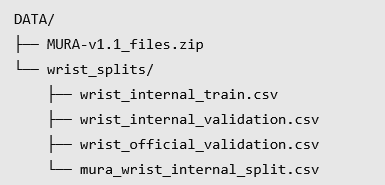

In [ ]:
import os

# Define the output directory based on your project DATA path
OUTPUT_DIR = "/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Map the split study-level UIDs back to individual image records from wrist_train
internal_train_images = wrist_train[wrist_train["study_uid"].isin(internal_train_studies["study_uid"])].copy()
internal_val_images = wrist_train[wrist_train["study_uid"].isin(internal_val_studies["study_uid"])].copy()

# Define output paths
train_csv_path = os.path.join(OUTPUT_DIR, "wrist_internal_train.csv")
val_csv_path = os.path.join(OUTPUT_DIR, "wrist_internal_val.csv")

# Save to CSV files
internal_train_images.to_csv(train_csv_path, index=False)
internal_val_images.to_csv(val_csv_path, index=False)

print("=== CSV EXPORT SUMMARY ===")
print(f"✓ Internal Train Images CSV saved to: {train_csv_path} ({len(internal_train_images):,} rows)")
print(f"✓ Internal Val Images CSV saved to:   {val_csv_path} ({len(internal_val_images):,} rows)")

In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/WRIST_SPLITS"
)

train = pd.read_csv(DATA_DIR / "wrist_internal_train.csv")
val = pd.read_csv(DATA_DIR / "wrist_internal_val.csv")

print("=== INTERNAL SPLIT VALIDATION ===")

print("Training images:", len(train))
print("Validation images:", len(val))

print("\nTraining studies:", train["study_uid"].nunique())
print("Validation studies:", val["study_uid"].nunique())

print("\nTraining patients:", train["patient_id"].nunique())
print("Validation patients:", val["patient_id"].nunique())

patient_overlap = (
    set(train["patient_id"]) &
    set(val["patient_id"])
)

study_overlap = (
    set(train["study_uid"]) &
    set(val["study_uid"])
)

print("\nPatient overlap:", len(patient_overlap))
print("Study overlap:", len(study_overlap))

assert len(train) + len(val) == 9756
assert len(patient_overlap) == 0
assert len(study_overlap) == 0

print("\n✓ Basic split validation PASSED")

In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA"
)

# Load original MURA file index
df = pd.read_csv(DATA_DIR / "mura_v1_1.csv")

# Select official wrist validation images
wrist_official_val = df[
    df["file_name"].astype(str).str.contains(
        r"(?:^|/)valid/XR_WRIST/",
        regex=True
    )
].copy()

print("Official wrist validation images:", len(wrist_official_val))
print("Columns:", wrist_official_val.columns.tolist())

assert len(wrist_official_val) == 659, (
    "Unexpected image count. Check the file index and paths."
)

# Save manifest
output_file = DATA_DIR / "wrist_official_validation.csv"
wrist_official_val.to_csv(output_file, index=False)

print("\n✓ Saved:", output_file)

Save the study-level split

In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA"
)

train = pd.read_csv(DATA_DIR / "WRIST_SPLITS/wrist_internal_train.csv")
val = pd.read_csv(DATA_DIR / "WRIST_SPLITS/wrist_internal_val.csv")

train_studies = train[
    ["patient_id", "study_uid", "label"]
].drop_duplicates().copy()
train_studies["internal_split"] = "train"

val_studies = val[
    ["patient_id", "study_uid", "label"]
].drop_duplicates().copy()
val_studies["internal_split"] = "validation"

split_record = pd.concat(
    [train_studies, val_studies],
    ignore_index=True
)

assert len(split_record) == 3460
assert split_record["study_uid"].is_unique

output = DATA_DIR / "mura_wrist_internal_split.csv"
split_record.to_csv(output, index=False)

print("✓ Saved:", output)
print(split_record["internal_split"].value_counts())

We have saved:
- wrist_internal_train.csv — 7,810 images, 2,769 studies
- wrist_internal_val.csv — 1,946 images, 691 studies
- wrist_official_validation.csv — 659 images
- mura_wrist_internal_split.csv — the exact internal study assignments

In [ ]:
import pandas as pd

labeled = pd.read_csv(
    DATA_DIR / "valid_labeled_studies.csv"
)

print("Columns:", labeled.columns.tolist())
print("\nFirst 5 rows:")
print(labeled.head().to_string(index=False))

In [ ]:
import pandas as pd

labeled = pd.read_csv(
    DATA_DIR / "valid_labeled_studies.csv",
    header=None,
    names=["study_path", "label"]
)

wrist_labeled = labeled[
    labeled["study_path"].str.contains(
        "/valid/XR_WRIST/", regex=False
    )
].copy()

print("Official wrist validation studies:", len(wrist_labeled))
print(wrist_labeled["label"].value_counts())

The official validation set is our locked final test set.

In [ ]:
output_file = DATA_DIR / "wrist_official_validation_studies.csv"

wrist_labeled.to_csv(output_file, index=False)

print("✓ Saved:", output_file)
print("Studies:", len(wrist_labeled))
print("Normal:", (wrist_labeled["label"] == 0).sum())
print("Abnormal:", (wrist_labeled["label"] == 1).sum())